# **Tarea 1 – Analítica de Datos (MACI 2026)**

**Alumno:** Keyden Urbina

**Mercado de celulares en Chile (solotodo.cl) y modelo de rango de precios**

Las cifras de las interpretaciones corresponden a la extracción del **08-11-2026 11:55** (web scraping del HTML, columna `fecha_extraccion`).

## Objetivo 2: Modelo de clasificación de rango de precio

### 2.1 Variable objetivo `rango_precio`

**Decisión clave:** se trabaja con **una fila por modelo nuevo con oferta liberada** (precio = mediana de sus tiendas). Si se usara una fila por tienda, el mismo celular (mismas características) podría quedar en train y en test, y el modelo "se sabría la respuesta". Los celulares sin oferta liberada no tienen precio, así que no pueden tener etiqueta.

**Variables:** solo las características técnicas limpias. La **marca se excluye a propósito**: los equipos de la emprendedora no tienen historia de marca, así que el modelo debe estimar el precio por lo que el teléfono *trae*, no por el logo. La marca se usa solo para imputar faltantes (2.2).

In [1]:
# Librerías que usa este notebook
import numpy as np                     # np.inf para el último tramo de precio
import pandas as pd                    # tablas
import matplotlib.pyplot as plt        # matriz de confusión e importancia de variables
from pathlib import Path               # rutas de carpetas

# Ruta a data/processed: la busca subiendo desde donde se ejecuta (sirve desde notebooks/ o desde la raíz)
PROC = next(p / "data" / "processed" for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "processed").is_dir())
print("Datos desde:", PROC / "data_processed.csv")

Datos desde: /Users/keydenurbina/Desktop/github/Proyecto Web Scraping/data/processed/data_processed.csv


In [2]:
from sklearn.model_selection import train_test_split, ParameterGrid, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

d = pd.read_csv(PROC / "data_processed.csv")
X_cols = ["memoria_gb", "ram_gb", "pantalla_pulg", "camara_principal_mp", "camara_frontal_mp", "bateria_mah", "peso_g", "nfc"]

# 1 fila por modelo nuevo con oferta liberada (precio = mediana entre tiendas). Si no, el mismo celular caería en train y test → trampa.
# La marca se guarda solo para imputar faltantes (Paso 2.2); NO es una variable del modelo.
m = d[d.es_nuevo == 1].groupby("nombre").agg({"marca": "first", **{c: "first" for c in X_cols}, "precio_oferta": "median"})
etiquetas = ["Muy bajo", "Bajo", "Medio", "Alto", "Muy alto"]
m["rango_precio"] = pd.cut(m.precio_oferta, [0, 100_000, 200_000, 320_000, 570_000, np.inf], labels=False, right=False)  # [a, b)
print(len(m), "modelos nuevos | con alguna característica vacía (se imputan en 2.2):", m[X_cols].isna().any(axis=1).sum())
m.rango_precio.value_counts().sort_index().rename(index=dict(enumerate(etiquetas)))

195 modelos nuevos | con alguna característica vacía (se imputan en 2.2): 24


rango_precio
Muy bajo     7
Bajo        42
Medio       49
Alto        39
Muy alto    58
Name: count, dtype: int64

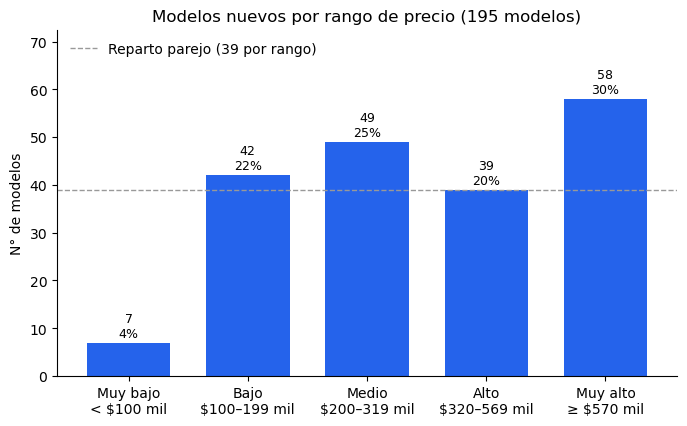

rango_precio
Muy bajo     7
Bajo        42
Medio       49
Alto        39
Muy alto    58
Name: count, dtype: int64

In [3]:
# Gráfico: cuántos modelos caen en cada rango de precio
conteo = m.rango_precio.value_counts().reindex(range(5), fill_value=0)     # n° de modelos por rango (0 a 4); si un rango queda vacío, pone 0
rangos = ["< $100 mil", "$100–199 mil", "$200–319 mil", "$320–569 mil", "≥ $570 mil"]
ax = conteo.plot.bar(figsize=(8, 4.5), color="#2563eb", width=0.7, rot=0)
ax.set_xticks(range(5), [f"{e}\n{r}" for e, r in zip(etiquetas, rangos)])  # etiqueta + rango de precio bajo cada barra
ax.bar_label(ax.containers[0], labels=[f"{v}\n{v/len(m):.0%}" for v in conteo], padding=2, fontsize=9)   # n° y % sobre cada barra
ax.axhline(len(m) / 5, color="#999", linestyle="--", linewidth=1,          # línea de referencia: si los 5 rangos fueran iguales
           label=f"Reparto parejo ({len(m) / 5:.0f} por rango)")
ax.legend(handles=ax.lines, loc="upper left", frameon=False)               # la leyenda solo explica la línea
ax.set_ylim(top=conteo.max() * 1.25)                                       # espacio para las etiquetas
ax.set(title=f"Modelos nuevos por rango de precio ({len(m)} modelos)", xlabel="", ylabel="N° de modelos")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

conteo.rename(index=dict(enumerate(etiquetas)))                            # la tabla se muestra debajo del gráfico

**Interpretación:**

- **"Muy bajo" es el problema:** solo 7 modelos (3,6%), 5,6 veces menos que un reparto parejo (39 por rango). Al dividir los datos queda **1 en validación y 1 en test**, así que su métrica en test será 0% o 100%: no permite sacar conclusiones sobre esa clase.

- **"Muy alto"** es la clase más grande (58 modelos, 30%), porque abarca todo lo que cuesta desde \$570 mil, sin límite superior.

**Este desbalance justifica tres decisiones del modelo:**

1. Dividir los datos estratificado (stratify).
2. Probar dar más peso a las clases chicas (class_weight="balanced") como hiperparámetro.
3. Elegir el modelo con el F1 macro, que pondera igual cada rango.

### 2.2 División train / validación / test + imputación sin fuga de datos
Primero se dividen los datos y **después** se imputan los faltantes de peso, batería y cámara frontal. La mediana de la marca (o la general, si la marca no tiene el dato) se aprende **solo con el conjunto de entrenamiento** y se aplica a validación y test. Al re-entrenar el ganador con train + validación (2.4), las medianas se vuelven a aprender con ese 80%.

In [4]:
X, y = m[X_cols], m.rango_precio
# 80% / 20% test → y del 80%, otro 80% / 20% para train / validación. stratify mantiene la proporción de cada rango.
X_80, X_te, y_80, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_80, y_80, test_size=0.2, stratify=y_80, random_state=42)
print("train", len(X_tr), "| val", len(X_val), "| test", len(X_te))

# Imputación SIN fuga de datos: las medianas se aprenden solo con el conjunto de entrenamiento y se aplican a los demás
def imputar(entrena, *otros):
    """Rellena los NaN con la mediana de la marca (o la general si la marca no tiene el dato), aprendida SOLO con `entrena`."""
    med_marca = entrena.groupby(m.marca[entrena.index]).median()             # mediana por marca, solo con entrenamiento
    med_general = entrena.median()                                           # respaldo: mediana de todo el entrenamiento
    rellenar = lambda X: X.fillna(med_marca.reindex(m.marca[X.index]).set_axis(X.index)).fillna(med_general)
    return [rellenar(X) for X in (entrena, *otros)]

X_tr_i, X_val_i = imputar(X_tr, X_val)                                       # para elegir hiperparámetros (2.3)
print("Celdas vacías antes de imputar → train:", X_tr.isna().sum().sum(), "| val:", X_val.isna().sum().sum(), "| test:", X_te.isna().sum().sum())
print("Después de imputar → train:", X_tr_i.isna().sum().sum(), "| val:", X_val_i.isna().sum().sum())

train 124 | val 32 | test 39
Celdas vacías antes de imputar → train: 15 | val: 4 | test: 7
Después de imputar → train: 0 | val: 0


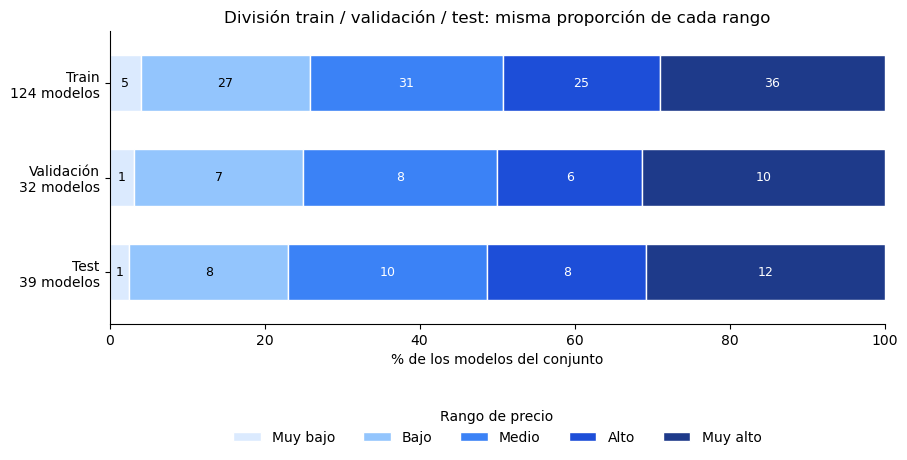

,Train,Validación,Test
Muy bajo,5,1,1
Bajo,27,7,8
Medio,31,8,10
Alto,25,6,8
Muy alto,36,10,12


In [5]:
# Gráfico: composición de cada conjunto por rango de precio (comprueba que stratify mantuvo las proporciones)
reparto = pd.DataFrame({"Train": y_tr.value_counts(), "Validación": y_val.value_counts(), "Test": y_te.value_counts()}
                       ).reindex(range(5), fill_value=0).set_axis(etiquetas)   # filas: rangos; columnas: conjuntos (n° de modelos)
pct = reparto / reparto.sum() * 100                                       # % dentro de cada conjunto (cada columna suma 100)
ax = pct.T.plot.barh(stacked=True, figsize=(10, 3.8), width=0.6, edgecolor="white",
                     color=["#dbeafe", "#93c5fd", "#3b82f6", "#1d4ed8", "#1e3a8a"])   # azul claro → oscuro = precio bajo → alto
for cont, rango, tinta in zip(ax.containers, etiquetas, ["black", "black", "white", "white", "white"]):
    ax.bar_label(cont, labels=[n if n else "" for n in reparto.loc[rango]], label_type="center", fontsize=9, color=tinta)   # n° de modelos
ax.set_yticks(range(3), [f"{s}\n{n} modelos" for s, n in reparto.sum().items()])   # nombre del conjunto + su tamaño
ax.invert_yaxis()                                                         # Train arriba
ax.set(title="División train / validación / test: misma proporción de cada rango", xlabel="% de los modelos del conjunto", xlim=(0, 100))
ax.legend(title="Rango de precio", loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=5, frameon=False)   # leyenda bajo el gráfico
ax.spines[["top", "right"]].set_visible(False)
plt.show()

reparto                                                                   # la tabla se muestra debajo del gráfico

**Interpretación:**

- Los 195 modelos quedan en **124 para entrenar, 32 para validar y 39 para test**: primero 80/20 para separar test, y luego 80/20 del resto para train y validación.

- **`Stratify`:** cada rango pesa casi lo mismo en los tres conjuntos. "Muy alto", por ejemplo, es el 29,0%, 31,3% y 30,8%, y "Medio", el 25,0%, 25,0% y 25,6%. Sin estratificar, por azar, algún conjunto podría quedar sin modelos "Muy bajo".

- **El límite de "Muy bajo":** con 7 modelos en total, quedan 5 para entrenar, **1 para validar y 1 para test**. Es una limitación de los datos, no del modelo.

- **Imputación:** 24 modelos tienen al menos una característica vacía (26 celdas: 15 en train, 4 en validación y 7 en test). Se rellenan con medianas aprendidas solo con el conjunto de entrenamiento; después de imputar no queda ninguna vacía.

### 2.3 Búsqueda de hiperparámetros (3 algoritmos, evaluados en validación)
Se prueban 3 algoritmos de complejidad creciente, cada uno con su grilla de hiperparámetros:
- **Regresión Logística:** modelo lineal, simple e interpretable. Necesita variables escaladas (`StandardScaler`).
- **Árbol de Decisión:** reglas del tipo "si RAM ≥ 8 GB y…", fáciles de explicar, pero tiende a sobreajustar.
- **Random Forest:** muchos árboles que votan. Suele ser más preciso y estable que un árbol solo.

Cada combinación se entrena con **train** y se evalúa con **validación**. Se elige la de mejor **F1 macro**: el promedio del F1 de los 5 rangos, que pondera igual la clase chica "Muy bajo" que la grande "Muy alto".

In [6]:
# Cada algoritmo con su grilla de hiperparámetros. Se elige la combinación con mejor F1 macro en VALIDACIÓN.
candidatos = {
    "Regresión Logística": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),   # escala: la logística lo necesita
                            {"logisticregression__C": [0.01, 0.1, 1, 10, 100], "logisticregression__class_weight": [None, "balanced"]}),
    "Árbol de Decisión": (DecisionTreeClassifier(random_state=42),
                          {"max_depth": [3, 5, 7, None], "min_samples_leaf": [1, 3, 5], "class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(random_state=42),
                      {"n_estimators": [200, 500], "max_depth": [5, 10, None], "min_samples_leaf": [1, 3], "class_weight": [None, "balanced"]}),
}   # class_weight="balanced" da más peso a los rangos con pocos celulares (ej. "Muy bajo")
res = {}
for nombre, (modelo, grilla) in candidatos.items():
    for p in ParameterGrid(grilla):                                               # prueba todas las combinaciones
        f1 = f1_score(y_val, modelo.set_params(**p).fit(X_tr_i, y_tr).predict(X_val_i), average="macro", zero_division=0)
        if f1 > res.get(nombre, (-1,))[0]: res[nombre] = (f1, p)                   # guarda la mejor

# Base de comparación: un "modelo" que siempre predice el rango más frecuente. Un buen modelo debe superarlo con holgura.
base = DummyClassifier(strategy="most_frequent").fit(X_tr_i, y_tr)
f1_base = f1_score(y_val, base.predict(X_val_i), average="macro", zero_division=0)
pd.DataFrame({**res, f"Base: siempre '{etiquetas[base.predict(X_val_i)[0]]}'": (f1_base, "—")},
             index=["F1 validación", "mejores hiperparámetros"]).T

,F1 validación,mejores hiperparámetros
Regresión Logística,0.665342,"{'logisticregression__C': 0.1, 'logisticregres..."
Árbol de Decisión,0.681818,"{'class_weight': None, 'max_depth': 7, 'min_sa..."
Random Forest,0.763557,"{'class_weight': None, 'max_depth': 10, 'min_s..."
Base: siempre 'Muy alto',0.095238,—


**Interpretación:**

- **Gana Random Forest** con F1 macro de **0,76** en validación, seguido del Árbol de Decisión (0,68) y la Regresión Logística (0,67).

- **Los tres superan con holgura a la base** que siempre predice "Muy alto" (F1 macro 0,10): aprenden algo de las características.

- **Hiperparámetros elegidos:** 200 árboles, profundidad máxima 10 y al menos 3 modelos por hoja. Exigir 3 modelos por hoja evita que el bosque "memorice" celulares sueltos. Dar más peso a las clases chicas (`class_weight="balanced"`) no mejoró la validación, así que quedó sin peso.

- **Ojo:** la validación tiene solo 32 modelos, con 1 solo "Muy bajo". La validación cruzada de abajo muestra cuánto puede variar ese número.

#### Validación cruzada (análisis complementario):

La elección anterior depende de una sola validación de 31 modelos. Como control, cada algoritmo, con los hiperparámetros elegidos, se evalúa con **validación cruzada de 5 particiones** sobre el 80% (train + validación). En cada partición la imputación se aprende solo con su parte de entrenamiento. El test no participa. La división exigida por la tarea se mantiene: este resultado no cambia la elección del modelo, solo muestra cuánto varía su F1.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)             # 5 particiones con la misma proporción de rangos
filas = {}
for nombre, (modelo, _) in candidatos.items():
    f1s = []
    for i_tr, i_va in cv.split(X_80, y_80):
        A, B = imputar(X_80.iloc[i_tr], X_80.iloc[i_va])                     # imputación aprendida solo con la parte de entrenamiento
        modelo.set_params(**res[nombre][1]).fit(A, y_80.iloc[i_tr])
        f1s.append(f1_score(y_80.iloc[i_va], modelo.predict(B), average="macro", zero_division=0))
    filas[nombre] = {"F1 medio (5 particiones)": np.mean(f1s), "desv. estándar": np.std(f1s), "mín.": min(f1s), "máx.": max(f1s)}
pd.DataFrame(filas).T.round(3)

,F1 medio (5 particiones),desv. estándar,mín.,máx.
Regresión Logística,0.484,0.093,0.371,0.634
Árbol de Decisión,0.485,0.106,0.330,0.636
Random Forest,0.499,0.074,0.404,0.606


**Interpretación:**

- **Con 5 particiones, los tres algoritmos quedan prácticamente empatados:** Random Forest 0,50, Árbol 0,49 y Logística 0,48. La diferencia (≤ 0,015) es mucho menor que la variación entre particiones (desviación de 0,07 a 0,11).

- **El F1 de validación (0,76) fue optimista:** en las particiones, el Random Forest va de 0,40 a 0,61. Una sola validación de 32 modelos puede salir alta o baja por azar.

- **Conclusión:** la elección del Random Forest es razonable (tiene el mejor promedio y la menor variación), pero no es una ventaja clara sobre los otros dos. Se mantiene la elección hecha con la validación.

### 2.4 Evaluación del mejor modelo en test
El ganador, **elegido antes con la validación (2.3)**, se re-entrena con train + validación y se evalúa **una sola vez** con **test**, datos que no vio en ningún momento. Así la métrica estima cómo le irá con celulares nuevos.

Junto a él se muestran, solo como contexto y sin cambiar la elección: una **base** que siempre predice el rango más frecuente, la **distancia en rangos** de cada predicción y la **tabla de errores**.

Mejor modelo: Random Forest | hiperparámetros: {'class_weight': None, 'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 200} 

              precision    recall  f1-score   support

    Muy bajo       0.00      0.00      0.00         1
        Bajo       0.67      0.75      0.71         8
       Medio       0.46      0.60      0.52        10
        Alto       0.43      0.38      0.40         8
    Muy alto       1.00      0.83      0.91        12

    accuracy                           0.64        39
   macro avg       0.51      0.51      0.51        39
weighted avg       0.65      0.64      0.64        39

Rango exacto: 25 de 39 (64%) | a lo más 1 rango de distancia: 39 (100%) | a 2 o más rangos: 0
Base (siempre 'Muy alto'): accuracy 0.31 | F1 macro 0.09


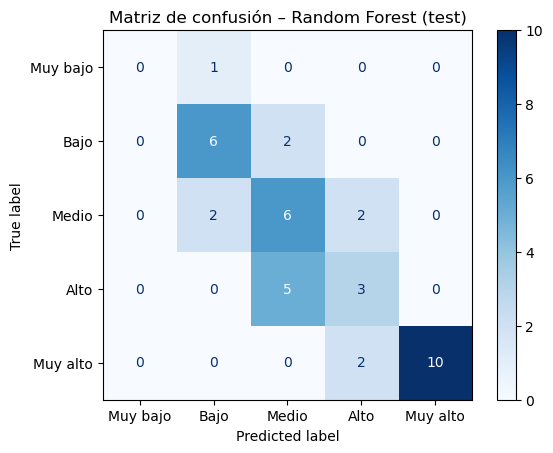

,precio,real,predicho,distancia
nombre,,,,
ZTE Nubia Music (128 GB / 4 GB / Yellow),89990.0,Muy bajo,Bajo,1
Motorola Moto G35 (256 GB / 4 GB / Black),119990.0,Bajo,Medio,1
Vivo Y18 (286 GB / 8 GB / Mocha Brown),159990.0,Bajo,Medio,1
Samsung Galaxy A07 5G (A076 / 128 GB / 4 GB / Gray) [SM-A076MZKBLTL],214990.0,Medio,Bajo,1
Samsung Galaxy A56 (A566 / 256 GB / 8 GB / Graphite) [SM-A566EZKCLTL],299990.0,Medio,Alto,1
Tecno Camon 40 Pro 4G (256 GB / 8 GB / Glacier White),299990.0,Medio,Alto,1
Motorola Moto Moto G37 (128 GB / 4 GB / Grey) [PBEF0008CL],314420.0,Medio,Bajo,1
Xiaomi Redmi Note 15 Pro 5G (256 GB / 8 GB / Black),364990.0,Alto,Medio,1
Honor Magic6 Lite (256 GB / 8 GB / Silver),399990.0,Alto,Medio,1


In [8]:
# El ganador (elegido en validación, 2.3) se re-entrena con train + validación (80%) y se evalúa UNA vez en test.
mejor = max(res, key=lambda k: res[k][0])
X_80_i, X_te_i = imputar(X_80, X_te)                                          # medianas aprendidas con el 80%, aplicadas a test
modelo = candidatos[mejor][0].set_params(**res[mejor][1]).fit(X_80_i, y_80)
pred = modelo.predict(X_te_i)
print("Mejor modelo:", mejor, "| hiperparámetros:", res[mejor][1], "\n")
print(classification_report(y_te, pred, labels=range(5), target_names=etiquetas, digits=2, zero_division=0))

# ¿A cuántos rangos de distancia quedan las predicciones? (0 = rango exacto)
dist = np.abs(pred - y_te.to_numpy())
print(f"Rango exacto: {(dist == 0).sum()} de {len(dist)} ({(dist == 0).mean():.0%}) | "
      f"a lo más 1 rango de distancia: {(dist <= 1).sum()} ({(dist <= 1).mean():.0%}) | a 2 o más rangos: {(dist >= 2).sum()}")

# Base de comparación en test (no compite: solo da contexto a las métricas del ganador)
pb = DummyClassifier(strategy="most_frequent").fit(X_80_i, y_80).predict(X_te_i)
print(f"Base (siempre '{etiquetas[pb[0]]}'): accuracy {accuracy_score(y_te, pb):.2f} | F1 macro {f1_score(y_te, pb, average='macro', zero_division=0):.2f}")

ConfusionMatrixDisplay.from_predictions(y_te, pred, labels=range(5), display_labels=etiquetas, cmap="Blues")
plt.title(f"Matriz de confusión – {mejor} (test)"); plt.show()

# Celulares mal clasificados: precio real, rango real y rango predicho
errores = pd.DataFrame({"precio": m.precio_oferta[X_te.index], "real": [etiquetas[i] for i in y_te],
                        "predicho": [etiquetas[i] for i in pred], "distancia": dist}, index=X_te.index)
errores[errores.distancia > 0].sort_values(["distancia", "precio"], ascending=[False, True])

**Interpretación:**

- **En test acierta el rango exacto en 25 de 39 celulares (accuracy 0,64).** El F1 macro es 0,51. La base que siempre predice "Muy alto" logra accuracy 0,31 y F1 macro 0,09: el modelo la duplica en accuracy, pero el resultado es **modesto**.

- **Por rango:**
  - **"Muy alto"** es el mejor (F1 0,91): reconoce 10 de 12, y cada vez que predice "Muy alto" acierta (precision 1,00).
  - **"Bajo"** (0,71) y **"Medio"** (0,52) quedan en un nivel intermedio.
  - **"Alto"** es el más difícil entre las clases grandes (F1 0,40): 5 de sus 8 celulares se clasifican como "Medio". Son equipos de 6–8 GB de RAM y 256–512 GB, como el Redmi Note 15 Pro 5G y el Honor Magic6 Lite, la misma configuración que muchos "Medio".
  - **"Muy bajo":** el modelo **no identificó el único caso de esta clase presente en test** (ZTE Nubia Music, \$89.990, clasificado como "Bajo"). Con un solo caso, la muestra es insuficiente para una conclusión sobre la clase.

- **Distancia de los errores (calculada en la celda):** los 14 errores quedan a **un rango de distancia**; ninguno salta dos o más. O sea, el 100 % de los celulares de test queda en su rango o en el vecino. 10 de los 14 errores subestiman el rango y 4 lo sobrestiman.

- **Cautela:** son 39 celulares. Un par de aciertos más o menos mueven la accuracy ~5 puntos.

#### ¿El test trae familias nuevas?

Un mismo modelo se vende en varias variantes (ej. Galaxy A17 de 128 y 256 GB). Si una variante queda en entrenamiento y otra en test, el modelo ya "conoce" esa familia. Aquí se mide cuántos celulares de test tienen otra variante de su familia en el 80 % de entrenamiento, y si el acierto cambia entre ambos grupos.

In [9]:
familia = pd.Series(m.index.str.replace(r" \(.*$", "", regex=True), index=m.index)   # nombre sin la variante: "Samsung Galaxy A17 4G"
conocida = familia[X_te.index].isin(familia[X_80.index]).to_numpy()         # True = su familia ya estaba en train/validación
print(f"Test: {conocida.sum()} de {len(conocida)} celulares tienen otra variante de su familia en train/validación")
for grupo, g in [("ya vista", conocida), ("nueva", ~conocida)]:              # acierto en cada grupo (si el grupo tiene celulares)
    if g.any(): print(f"Familia {grupo}: {g.sum()} celulares | rango exacto {(dist[g] == 0).mean():.0%} | a lo más 1 rango {(dist[g] <= 1).mean():.0%}")


Test: 0 de 39 celulares tienen otra variante de su familia en train/validación
Familia nueva: 39 celulares | rango exacto 64% | a lo más 1 rango 100%


**Interpretación:** 

Ninguno de los 39 celulares de test comparte familia con los de entrenamiento: todos son familias que el modelo no vio. Por eso el 64% de acierto exacto mide generalización a **modelos nuevos**, no a otra variante de un modelo conocido. La familia se define por el nombre sin la variante entre paréntesis, así que dos equipos de una misma línea con distinto nombre (ej. "A17 4G" y "A17 5G") cuentan como familias distintas.

### 2.5 Variables más influyentes
**Importancia por permutación:** se desordena una variable a la vez en test y se mide cuánto cae el F1. Si al desordenarla el modelo empeora mucho, esa variable era importante. Sirve para cualquier algoritmo. Se repite 30 veces: el gráfico muestra la **caída media** y su **desviación estándar**, para ver qué diferencias son claras y cuáles caben en el ruido.

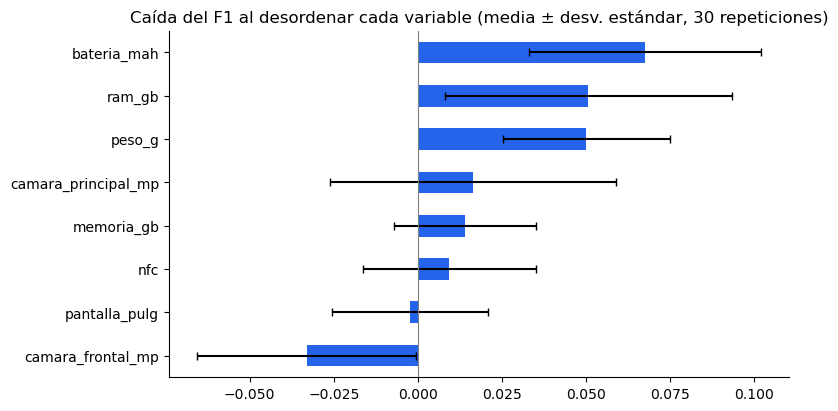

,caída media del F1,desv. estándar
bateria_mah,0.067,0.034
ram_gb,0.051,0.043
peso_g,0.050,0.025
camara_principal_mp,0.016,0.043
memoria_gb,0.014,0.021
nfc,0.009,0.026
pantalla_pulg,-0.002,0.023
camara_frontal_mp,-0.033,0.033


In [10]:
# Importancia por permutación: cuánto cae el F1 si "desordenamos" una variable (sirve para cualquier modelo).
# Se repite 30 veces: la barra es la caída media y la línea negra, ± 1 desviación estándar entre repeticiones.
imp = permutation_importance(modelo, X_te_i, y_te, scoring="f1_macro", n_repeats=30, random_state=42)
tabla = pd.DataFrame({"caída media del F1": imp.importances_mean, "desv. estándar": imp.importances_std}, index=X_cols).sort_values("caída media del F1")
ax = tabla["caída media del F1"].plot.barh(xerr=tabla["desv. estándar"], capsize=3, color="#2563eb", figsize=(8, 4.5))
ax.axvline(0, color="gray", linewidth=0.8)                                   # a la izquierda de 0: desordenarla no empeora el modelo
ax.set(title="Caída del F1 al desordenar cada variable (media ± desv. estándar, 30 repeticiones)", xlabel="", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
tabla.sort_values("caída media del F1", ascending=False).round(3)

**Interpretación:**

- **Tres variables tienen un efecto claramente mayor que cero:** batería (0,067 ± 0,034), RAM (0,051 ± 0,043) y peso (0,050 ± 0,025). En las tres, la caída media supera su desviación estándar.

- **Entre esas tres no hay un orden claro:** sus intervalos se superponen, así que no se puede afirmar cuál es la más influyente.

- **Cámara principal, memoria, NFC y pantalla** tienen caídas medias de −0,002 a 0,016, menores que su desviación estándar: con estos datos **no se distinguen de un efecto nulo**. En la memoria se suma que se superpone con la RAM (equipos con más RAM traen más memoria), así que al desordenarla el modelo sigue informándose por la RAM.

- **La cámara frontal sale negativa (−0,033 ± 0,033):** desordenarla no empeora el modelo, e incluso lo mejora levemente. Es compatible con que esa variable solo agregue ruido.

- **Ojo:** la importancia se mide sobre los 39 celulares de test y describe lo que usa **este** modelo, no una relación causal entre la característica y el precio. La batería, por ejemplo, ayuda a separar rangos porque en la gama de entrada son frecuentes las baterías grandes (pregunta a).

### 2.6 Conclusión del Objetivo 2

- **Mejor modelo: Random Forest**, elegido por F1 macro en validación (0,76). En test logra **accuracy 0,64 y F1 macro 0,51**, frente a 0,31 y 0,09 de la base que siempre predice "Muy alto". Todos sus errores en test quedan a un rango de distancia.

- **Es un resultado modesto.** La validación cruzada ubica su F1 macro alrededor de 0,50 (entre 0,40 y 0,61 según la partición), muy cerca del árbol y de la regresión logística.

- **Para la emprendedora:** el modelo sirve como **referencia exploratoria** para ubicar un equipo en un rango de precio aproximado a partir de sus características. **No está suficientemente validado para fijar precios directamente:** confunde "Alto" con "Medio" y no tiene evidencia suficiente sobre "Muy bajo". Las características que más usa son la batería, la RAM y el peso, sin un orden claro entre ellas.

- **Limitaciones:**
  1. **"Muy bajo":** son 7 modelos en total y 1 en test. El modelo no identificó ese caso, pero la muestra es insuficiente para saber si la clase se puede predecir.
  2. **Muestras pequeñas** (195 modelos; 32 en validación y 39 en test): las métricas cambian varios puntos con otra división, y la diferencia entre los tres algoritmos está dentro de esa variación.
  3. **Variables no incluidas:** el procesador y la tasa de refresco, que distinguen gamas, y la marca, que se excluye a propósito porque los equipos de la emprendedora no tienen historia de marca.
  4. **Una sola fecha:** los precios son de una extracción (08-11-2026); el rango de un mismo equipo puede cambiar con ofertas o con el tiempo.